In [256]:
from pystormtracker.models.tracks import Tracks, TracksMetadata
from pystormtracker.metrics.compare import compare_tracks, TrackComparisonConfig
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import pandas as pd
import pystormtracker as pst
from pathlib import Path
import cartopy.crs as ccrs

import sys
import os

module_dir = (Path.cwd() / ".."/".." / "algorithms").resolve()
sys.path.insert(0,str(module_dir))
import validation as val
import processing as pro


import importlib
importlib.reload(val)  # pick up edits in validation.py without restarting the kernel
importlib.reload(pro)  # pick up edits in processing.py without restarting the kernel

import importlib

In [257]:
def _in_box(lat, lon, box):
    lon_min, lon_max, lat_min, lat_max = box
    return (lon >= lon_min) & (lon <= lon_max) & (lat >= lat_min) & (lat <= lat_max)
 
 
def dataframe_to_tracks(df, variable="vo", units="s^-1", mode="max", scale=1.0):
    """
    Convert a per-point DataFrame (track_id, time, lat, lon, <column>) to a Tracks object.
 
    variable : name the intensity gets in the Tracks object (use the same name as your
               own tracks, e.g. "vo", so intensities can be compared)
    scale    : multiply the intensity by this. TRACK files usually store vorticity in
               units of 1e-5 s-1, so use scale=1e-5 to get s-1 like ERA5 'vo'.
    The intensity is read from the column `variable`, or 'vorticity' if that is absent.
    """
    col = variable if variable in df.columns else "vorticity"
    df = df.dropna(subset=["lat", "lon", "time"]).sort_values(["track_id", "time"], kind="stable")
    counts = df.groupby("track_id", sort=False).size()
    offsets = np.concatenate([[0], np.cumsum(counts.to_numpy())])
    times_ms = (pd.DatetimeIndex(df["time"]).as_unit("ms").asi8).astype(np.int64)
    meta = TracksMetadata(primary_variable=variable, mode=mode, units={variable: units})
    return Tracks(
        ids=counts.index.to_numpy(dtype=np.int64),
        offsets=offsets,
        times=times_ms,
        lats=df["lat"].to_numpy(float),
        lons=df["lon"].to_numpy(float),
        variables={variable: df[col].to_numpy(float) * scale},
        metadata=meta,
    )
 

def clip_to_domain(df, domain, time_range):
    lon_min, lon_max, lat_min, lat_max = domain
    t0, t1 = map(pd.Timestamp, time_range)
    m = (df["lon"].between(lon_min, lon_max) & df["lat"].between(lat_min, lat_max)
         & df["time"].between(t0, t1))
    out = df[m].sort_values(["track_id", "time"]).copy()
    gap = out.groupby("track_id")["time"].diff() > pd.Timedelta(hours=6)
    out["segment"] = gap.groupby(out["track_id"]).cumsum()
    out["track_id"] = out["track_id"] * 100 + out["segment"]   # unique id per piece
    return out

def clip_tracks(tracks, box=None, time_range=None, min_points=1):
    """
    Keep only the points of each track inside `box` (lon_min, lon_max, lat_min, lat_max)
    and `time_range`, so both datasets are compared over the same window.
 
    A track that leaves and re-enters the box keeps both pieces under its original id
    (the gap is just missing times, which compare_tracks handles).
    Tracks with fewer than `min_points` remaining points are dropped.
    """
    t = np.asarray(tracks.times)
    keep = np.ones(t.size, dtype=bool)
    if box is not None:
        keep &= _in_box(np.asarray(tracks.lats), np.asarray(tracks.lons), box)
    if time_range is not None:
        t0, t1 = (np.datetime64(pd.Timestamp(x), "ms").astype(np.int64) for x in time_range)
        keep &= (t >= t0) & (t <= t1)
 
    point_ids = np.repeat(np.asarray(tracks.ids), np.diff(tracks.offsets))
    ids, counts = [], []
    for tid in np.asarray(tracks.ids):  # preserve original order
        n = int(keep[point_ids == tid].sum())
        if n >= min_points:
            ids.append(tid)
            counts.append(n)
    sel = keep & np.isin(point_ids, ids)
 
    return Tracks(
        ids=np.asarray(ids, dtype=np.int64),
        offsets=np.concatenate([[0], np.cumsum(counts)]).astype(np.int64),
        times=t[sel],
        lats=np.asarray(tracks.lats)[sel],
        lons=np.asarray(tracks.lons)[sel],
        variables={k: np.asarray(v)[sel] for k, v in tracks.variables.items()},
        metadata=tracks.metadata,
    )
 
 
def compare_to_validation(reference, candidate, matching="global_assignment",
                          max_mean_separation_deg=2.0, min_overlap_fraction=0.6,
                          variable=None):
    """
    Run compare_tracks and return (result, per-match DataFrame).
 
    matching : "nearest"           -> TRACK's own rule (a candidate can be reused)
               "mutual_nearest"    -> reciprocal nearest pairs only
               "global_assignment" -> one-to-one; gives tp/fp/fn, precision, recall, f1
    variable : intensity variable to compare along matched pairs (units must be identical
               in both Tracks objects), or None to skip intensity statistics.
    """
    cfg = TrackComparisonConfig(matching=matching,
                                max_mean_separation_deg=max_mean_separation_deg,
                                min_overlap_fraction=min_overlap_fraction,
                                variable=variable)
    res = compare_tracks(reference, candidate, config=cfg)
    rows = []
    for m in res.matches:
        row = {
            "reference_id": m.reference_id, "candidate_id": m.candidate_id,
            "overlap_fraction": m.overlap_fraction, "overlap_count": m.overlap_count,
            "mean_sep_km": m.mean_separation_km, "max_sep_km": m.maximum_separation_km,
            "ref_points": m.reference.point_count, "cand_points": m.candidate.point_count,
            "ref_peak": m.reference.peak_intensity, "cand_peak": m.candidate.peak_intensity,
            "n_eligible_candidates": m.eligible_candidate_count,
        }
        if m.intensity_difference is not None:
            row.update(intensity_bias=m.intensity_difference.bias,
                       intensity_rmse=m.intensity_difference.rmse)
        rows.append(row)
    return res, pd.DataFrame(rows)

In [258]:
REGION = (-80, 20, 30, 80)   # smaller region for tracking, limited by the domain, 10 deg smaller
DOMAIN = (-90, 30, 20, 90)   # tracking domain (region + buffer), limited by the downloaded data
TIME_RANGE = ('1998-12-01 00:00:00', '1999-02-28 18:00:00')  # time range for the validation tracks

df_validation = val.load_tracks('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/validation_tracks_data/ERA5_19981999_TRACKS_FILTERED_pos.addmslp', start_time=TIME_RANGE[0], end_time=TIME_RANGE[1])


In [259]:
df_validation

,step,lon,lat,vorticity,mslp_lon,mslp_lat,mslp,track_id,time
obs,,,,,,,,,
0,1,0.487187,45.558174,2.945488,NaN,NaN,1024.025,3,1998-12-01 00:00:00
1,2,-2.346924,44.636440,2.743430,359.6110,42.38197,1017.109,3,1998-12-01 06:00:00
2,3,-7.956207,39.646866,3.258656,NaN,NaN,1017.025,3,1998-12-01 12:00:00
3,4,-9.561157,37.609779,3.978987,NaN,NaN,1012.945,3,1998-12-01 18:00:00
4,5,-9.764160,36.040455,4.625281,352.7589,35.01079,1010.072,3,1998-12-02 00:00:00
...,...,...,...,...,...,...,...,...,...
8523,351,174.133652,85.109848,3.723335,NaN,NaN,1024.317,2562,1999-02-26 12:00:00
8524,352,161.192886,84.471527,3.298671,NaN,NaN,1028.030,2562,1999-02-26 18:00:00
8525,353,150.237457,83.856377,2.820443,NaN,NaN,1031.977,2562,1999-02-27 00:00:00


In [260]:
#rename vorticity col as 'vo':
df_validation=df_validation.rename(columns={'vorticity': 'vo'})

In [261]:
df_validation

,step,lon,lat,vo,mslp_lon,mslp_lat,mslp,track_id,time
obs,,,,,,,,,
0,1,0.487187,45.558174,2.945488,NaN,NaN,1024.025,3,1998-12-01 00:00:00
1,2,-2.346924,44.636440,2.743430,359.6110,42.38197,1017.109,3,1998-12-01 06:00:00
2,3,-7.956207,39.646866,3.258656,NaN,NaN,1017.025,3,1998-12-01 12:00:00
3,4,-9.561157,37.609779,3.978987,NaN,NaN,1012.945,3,1998-12-01 18:00:00
4,5,-9.764160,36.040455,4.625281,352.7589,35.01079,1010.072,3,1998-12-02 00:00:00
...,...,...,...,...,...,...,...,...,...
8523,351,174.133652,85.109848,3.723335,NaN,NaN,1024.317,2562,1999-02-26 12:00:00
8524,352,161.192886,84.471527,3.298671,NaN,NaN,1028.030,2562,1999-02-26 18:00:00
8525,353,150.237457,83.856377,2.820443,NaN,NaN,1031.977,2562,1999-02-27 00:00:00


In [262]:
df_validation = clip_to_domain(df_validation, DOMAIN, TIME_RANGE)

In [263]:
df_validation

,step,lon,lat,vo,mslp_lon,mslp_lat,mslp,track_id,time,segment
obs,,,,,,,,,,
0,1,0.487187,45.558174,2.945488,NaN,NaN,1024.025,300,1998-12-01 00:00:00,0
1,2,-2.346924,44.636440,2.743430,359.611000,42.38197,1017.109,300,1998-12-01 06:00:00,0
2,3,-7.956207,39.646866,3.258656,NaN,NaN,1017.025,300,1998-12-01 12:00:00,0
3,4,-9.561157,37.609779,3.978987,NaN,NaN,1012.945,300,1998-12-01 18:00:00,0
4,5,-9.764160,36.040455,4.625281,352.758900,35.01079,1010.072,300,1998-12-02 00:00:00,0
...,...,...,...,...,...,...,...,...,...,...
8515,343,-4.481384,87.375290,4.770901,5.318585,88.59691,1003.996,256200,1999-02-24 12:00:00,0
8516,344,-13.983551,87.335152,4.309511,346.116100,89.07852,1004.317,256200,1999-02-24 18:00:00,0
8517,345,-72.188629,87.176979,4.677020,292.363900,86.30700,1003.551,256200,1999-02-25 00:00:00,0


In [264]:
tracks_validation = dataframe_to_tracks(df_validation, variable = 'vo', scale=1e-5)  # convert to s^-1

In [265]:
tracks_validation, summary_validation, points_validation = pro.postprocess_tracks(tracks_validation, region=REGION, domain=DOMAIN, time_range=TIME_RANGE,
                       region_criterion="passes", min_points_in_region=1,
                       rsplice_min_points=8, rsplice_max_points=None,
                       rsplice_distance_degrees=9.0, rsplice_distance_mode="endpoint",
                       rsplice_cadence=np.timedelta64(6, "h"),
                       min_peak=None, max_frac_at_edge=0.5,
                       edge_buffer_deg=2.5, drop_time_truncated=False)

In [266]:
summary_validation['vo_peak']

0      0.000046
1      0.000116
2      0.000061
3      0.000073
4      0.000037
         ...   
203    0.000038
204    0.000098
205    0.000026
206    0.000044
207    0.000048
Name: vo_peak, Length: 208, dtype: float64

In [267]:
report = pro.filter_report(summary_validation)
report

raw tracks: 208, kept: 121


,removed_by_this_criterion,removed_only_by_this_criterion
rsplice,81,31
region,56,4
edge,15,0
peak,0,0
time,0,0


/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


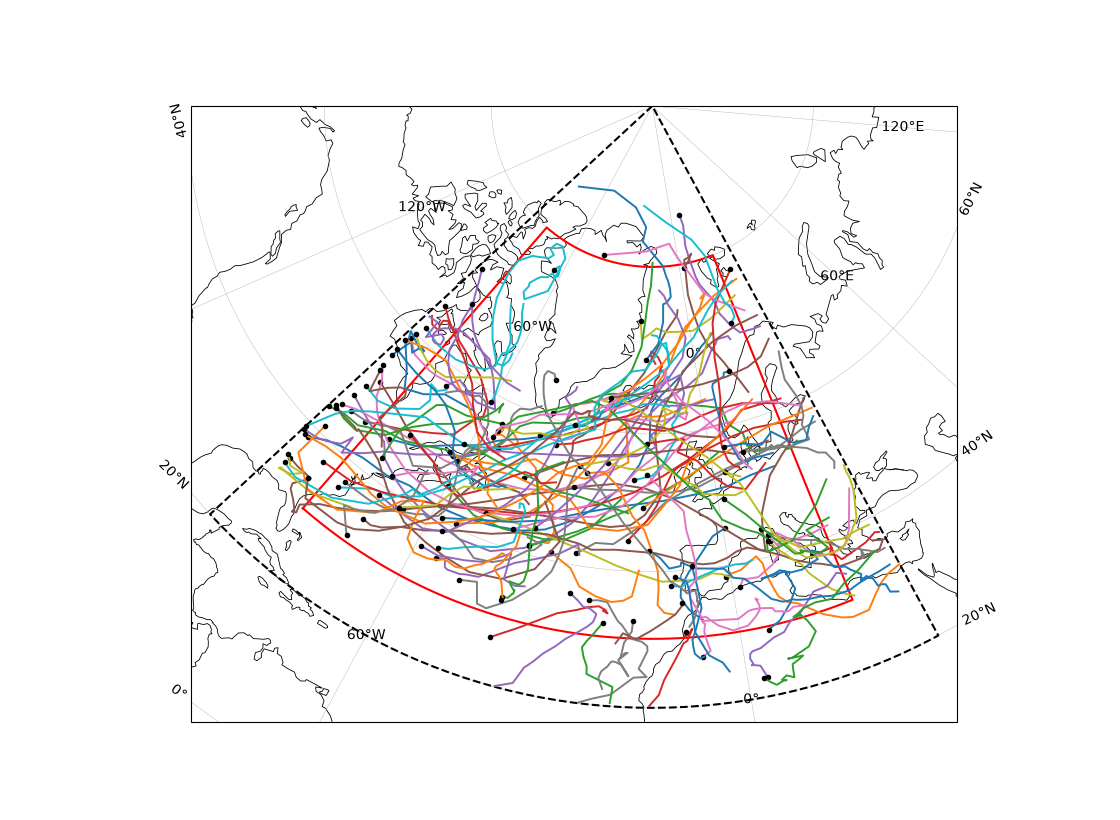

In [268]:
ax = val.plot_regional_tracks(tracks_validation, region=REGION, domain=DOMAIN, summary = summary_validation, object=True)

In [269]:
tracks = pst.load_tracks('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/trackjson/19981999_DJF_vo.trackjson')

In [270]:
tracks, summary, points = pro.postprocess_tracks(tracks, region=REGION, domain=DOMAIN, time_range=TIME_RANGE,
                       region_criterion="passes", min_points_in_region=1,
                       rsplice_min_points=8, rsplice_max_points=None,
                       rsplice_distance_degrees=9.0, rsplice_distance_mode="endpoint",
                       rsplice_cadence=np.timedelta64(6, "h"),
                       min_peak=None, max_frac_at_edge=0.5,
                       edge_buffer_deg=2.5, drop_time_truncated=False)

In [271]:
report = pro.filter_report(summary)

raw tracks: 2036, kept: 403


In [272]:
comparison, matches_df = compare_to_validation(tracks_validation, tracks, matching="global_assignment",
                                               max_mean_separation_deg=2.0, min_overlap_fraction=0.6,
                                               variable="vo")

In [273]:
matches_df

,reference_id,candidate_id,overlap_fraction,overlap_count,mean_sep_km,max_sep_km,ref_points,cand_points,ref_peak,cand_peak,n_eligible_candidates,intensity_bias,intensity_rmse
0,700,29,0.958333,23,95.734488,263.410358,23,25,0.000116,0.000240,1,0.000063,0.000068
1,5300,500,0.814815,11,185.469760,518.289244,14,13,0.000032,0.000120,1,0.000056,0.000067
2,7900,746,0.800000,16,111.867930,595.464520,24,16,0.000120,0.000248,1,0.000067,0.000077
3,10400,680,0.684211,13,151.395446,345.975839,17,21,0.000021,0.000051,1,0.000019,0.000020
4,20600,161,0.885246,27,123.289436,421.066579,27,34,0.000100,0.000242,1,0.000060,0.000070
5,23100,386,0.941176,8,198.557344,347.069487,8,9,0.000037,0.000061,1,0.000021,0.000021
6,29100,405,0.964706,41,123.538702,529.752413,42,43,0.000087,0.000185,1,0.000039,0.000048
7,31600,257,0.888889,12,80.412771,183.133589,12,15,0.000051,0.000098,1,0.000035,0.000036
8,37800,423,0.967742,15,137.450006,510.489282,16,15,0.000125,0.000244,1,0.000087,0.000091
9,45300,875,0.941176,16,108.839841,260.429220,17,17,0.000050,0.000096,1,0.000024,0.000027


In [274]:
# result table 
results_df = pd.Series({
    "Hits": int(len(matches_df)),
    "Miss": int(len(tracks_validation) - len(matches_df)),
    "Extra": int(len(tracks) - len(matches_df)),
    "F1": comparison.f1, #
    "Precision": comparison.precision,
    "Recall": comparison.recall,
    "True positives": comparison.tp,
    "False positives": comparison.fp,
    "False negatives": comparison.fn,
})
results_df

Hits                46.000000
Miss                75.000000
Extra              357.000000
F1                   0.175573
Precision            0.114144
Recall               0.380165
True positives      46.000000
False positives    357.000000
False negatives     75.000000
dtype: float64

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


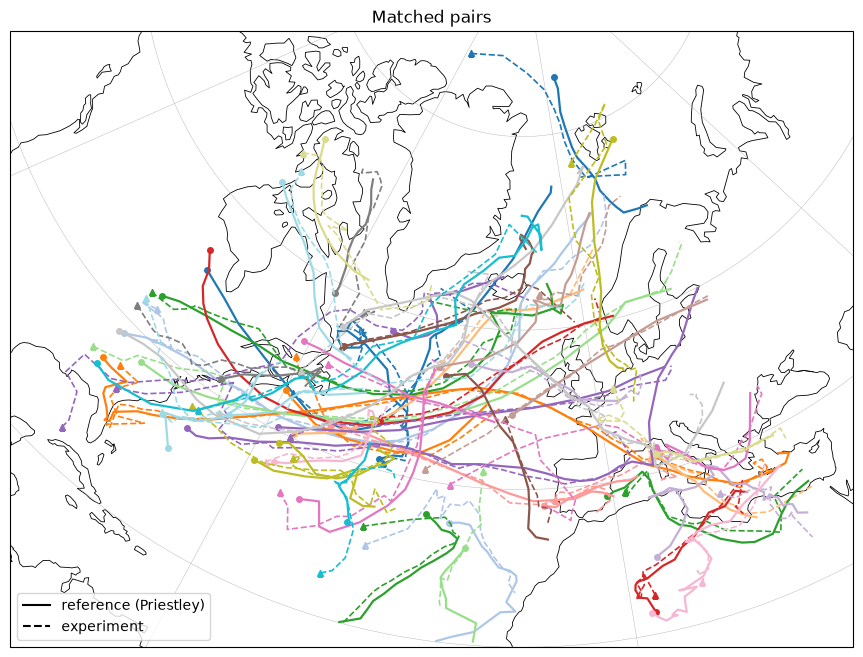

In [276]:
pc = ccrs.PlateCarree()
proj = ccrs.LambertConformal(central_longitude=-15, central_latitude=55)

# look up tracks by id
ref_by_id = {tr.track_id: tr for tr in tracks_validation}
cand_by_id = {tr.track_id: tr for tr in tracks}

fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={"projection": proj})
ax.coastlines(linewidth=0.6)
ax.gridlines(linewidth=0.3)
ax.set_extent([DOMAIN[0], DOMAIN[1], DOMAIN[2], 85], crs=pc)

colors = plt.cm.tab20(np.linspace(0, 1, len(matches_df)))
for row, c in zip(matches_df.itertuples(), colors):
    ref = ref_by_id[int(row.reference_id)]
    cand = cand_by_id[int(row.candidate_id)]
    ax.plot(ref.lons, ref.lats, "-", color=c, lw=1.6, transform=pc)
    ax.plot(cand.lons, cand.lats, "--", color=c, lw=1.2, transform=pc)
    ax.plot(ref.lons[0], ref.lats[0], "o", color=c, ms=4, transform=pc)    # reference start
    ax.plot(cand.lons[0], cand.lats[0], "^", color=c, ms=4, transform=pc)  # experiment start

ax.plot([], [], "k-", label="reference (Priestley)")
ax.plot([], [], "k--", label="experiment")
ax.legend(loc="lower left")
ax.set_title(f"Matched pairs")
plt.show()

Number of verified tracks: 46
Number of discarded tracks: 357
Number of missed tracks: 75


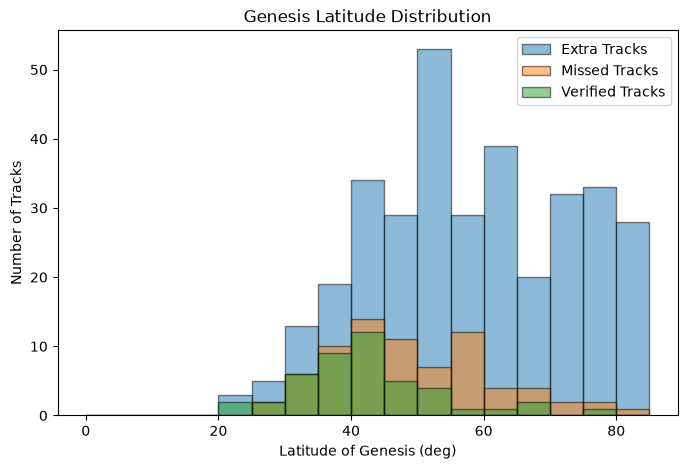

In [277]:
#creating list for verified
verified_tracks = matches_df['candidate_id']

#remember to filter the summary dataframes to only include the tracks that were kept
summary_val_filtered = summary_validation[summary_validation['keep'] == True]
summary_filtered = summary[summary['keep'] == True]


kept_tracks = summary_filtered[summary_filtered['track_id'].isin(verified_tracks)]
extra_tracks = summary_filtered[~summary_filtered['track_id'].isin(verified_tracks)]
missed_tracks = summary_val_filtered[~summary_val_filtered['track_id'].isin(matches_df['reference_id'])]


print(f"Number of verified tracks: {len(kept_tracks)}")
print(f"Number of discarded tracks: {len(extra_tracks)}")
print(f"Number of missed tracks: {len(missed_tracks)}")



genesis_vals = kept_tracks["lat_genesis"].values
genesis_missed = missed_tracks["lat_genesis"].values
genesis_ex = extra_tracks["lat_genesis"].values

counts, edges = np.histogram(genesis_vals, bins=np.arange(0, 90, 5), density=False)
counts_missed, edges_missed = np.histogram(genesis_missed, bins=np.arange(0, 90, 5), density=False)
counts_dis, edges_dis = np.histogram(genesis_ex, bins=np.arange(0, 90, 5), density=False)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(edges_dis[:-1], counts_dis, width=5, align="edge", edgecolor="black", label="Extra Tracks", alpha=0.5)
ax.bar(edges_missed[:-1], counts_missed, width=5, align="edge", edgecolor="black", label="Missed Tracks", alpha=0.5)
ax.bar(edges[:-1], counts, width=5, align="edge", edgecolor="black", label="Verified Tracks", alpha=0.5)

ax.set_xlabel("Latitude of Genesis (deg)")
ax.set_ylabel("Number of Tracks")
ax.set_title("Genesis Latitude Distribution")
ax.legend()

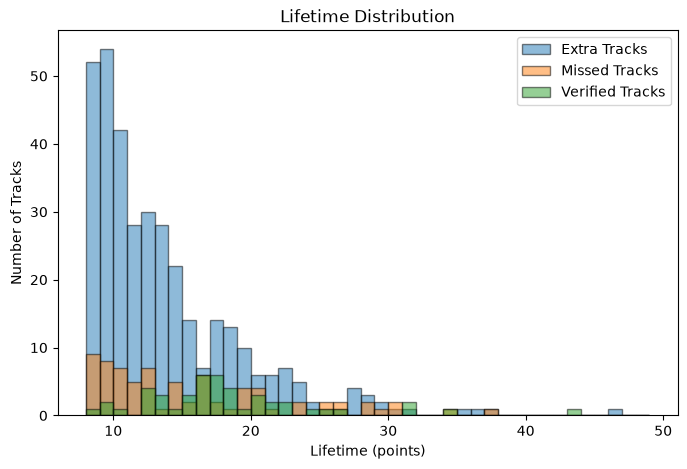

In [278]:
lifetime_vals = kept_tracks["n_points"].values
lifetime_missed = missed_tracks["n_points"].values
lifetime_ex = extra_tracks["n_points"].values

counts, edges = np.histogram(lifetime_vals, bins=np.arange(8, 50, 1))
counts_missed, edges_missed = np.histogram(lifetime_missed, bins=np.arange(8, 50, 1))
counts_dis, edges_dis = np.histogram(lifetime_ex, bins=np.arange(8, 50, 1))

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(edges_dis[:-1], counts_dis, width=1, align="edge", edgecolor="black", label="Extra Tracks", alpha=0.5)
ax.bar(edges_missed[:-1], counts_missed, width=1, align="edge", edgecolor="black", label="Missed Tracks", alpha=0.5)
ax.bar(edges[:-1], counts, width=1, align="edge", edgecolor="black", label="Verified Tracks", alpha=0.5)

ax.set_xlabel("Lifetime (points)")
ax.set_ylabel("Number of Tracks")
ax.set_title("Lifetime Distribution")
ax.legend()

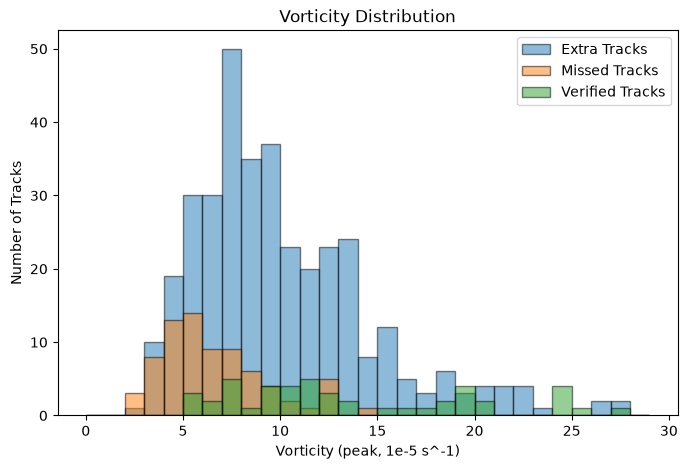

In [282]:
vo_peak_vals = kept_tracks["vo_peak"].values*1e5
vo_peak_missed = missed_tracks["vo_peak"].values*1e5
vo_peak_ex = extra_tracks["vo_peak"].values*1e5

counts, edges = np.histogram(vo_peak_vals, bins=np.arange(0, 30, 1))
counts_missed, edges_missed = np.histogram(vo_peak_missed, bins=np.arange(0, 30, 1))
counts_dis, edges_dis = np.histogram(vo_peak_ex, bins=np.arange(0, 30, 1))

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(edges_dis[:-1], counts_dis, width=1, align="edge", edgecolor="black", label="Extra Tracks", alpha=0.5)
ax.bar(edges_missed[:-1], counts_missed, width=1, align="edge", edgecolor="black", label="Missed Tracks", alpha=0.5)
ax.bar(edges[:-1], counts, width=1, align="edge", edgecolor="black", label="Verified Tracks", alpha=0.5)

ax.set_xlabel("Vorticity (peak, 1e-5 s^-1)")
ax.set_ylabel("Number of Tracks")
ax.set_title("Vorticity Distribution")
ax.legend()

Number of extra tracks: 357
Number of extra tracks plotted: 357


/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


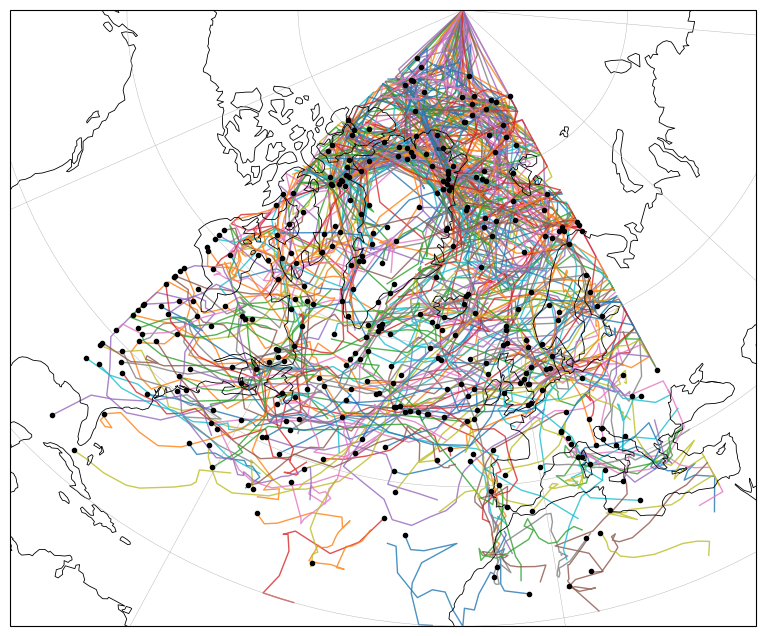

In [280]:
pc = ccrs.PlateCarree()
proj = ccrs.LambertConformal(central_longitude=-15, central_latitude=55)



fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={"projection": proj})
ax.coastlines(linewidth=0.6)
ax.gridlines(linewidth=0.3)
ax.set_extent([DOMAIN[0], DOMAIN[1], DOMAIN[2], 90], crs=pc)
i =0
print(f"Number of extra tracks: {len(extra_tracks)}")
for tr in tracks:
    if tr.track_id in extra_tracks['track_id'].values:
        ax.plot(tr.lons, tr.lats, "-", alpha=0.8, lw=1, transform=pc, zorder=0)
        ax.plot(tr.lons[0], tr.lats[0], "k.", ms=6, transform=pc)
        i+=1
print(f"Number of extra tracks plotted: {i}")


75
Number of missed tracks plotted: 75


/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


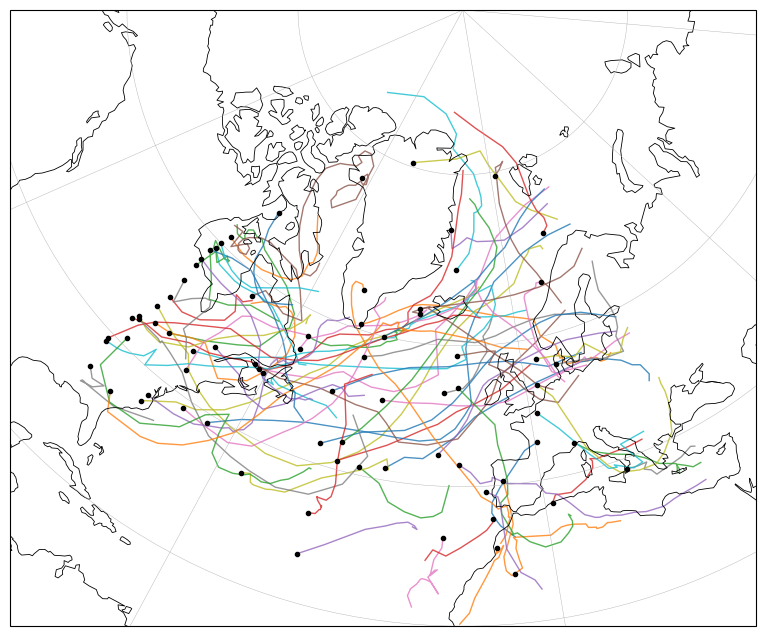

In [281]:
pc = ccrs.PlateCarree()
proj = ccrs.LambertConformal(central_longitude=-15, central_latitude=55)

fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={"projection": proj})
ax.coastlines(linewidth=0.6)
ax.gridlines(linewidth=0.3)
ax.set_extent([DOMAIN[0], DOMAIN[1], DOMAIN[2], 90], crs=pc)

print(len(missed_tracks.values))
i=0
for tr in tracks_validation:
    if tr.track_id in missed_tracks['track_id'].values:
        ax.plot(tr.lons, tr.lats, "-", alpha=0.8, lw=1, transform=pc, zorder=0)
        ax.plot(tr.lons[0], tr.lats[0], "k.", ms=6, transform=pc)
        i+=1

print(f"Number of missed tracks plotted: {i}")
